# 🩺 피마 인디언 당뇨병 데이터 분석 & 머신러닝 예측 실습
이 노트북은 데이터 분석에 처음 입문하는 분들을 위한 실습 가이드입니다.
기초 데이터 탐색부터 결측치/이상치 정제, 시각화, 그리고 당뇨병 발병 여부를 예측하는 머신러닝 모델 구축까지 단계별로 구성되어 있습니다.

---
### 📌 목차
1. **환경 설정 및 데이터 로드**
2. **결측치, 중복값, 이상치 검증 및 정제**
3. **탐색적 데이터 분석 (EDA) & 시각화**
   - 당뇨 유무(Outcome)별 주요 지표 분포 비교
   - 변수 간 상관관계 히트맵 (Correlation Matrix)
4. **머신러닝 데이터셋 준비 (Train / Test 분할 및 결측치 대체, 스케일링)**
5. **예측 모델 구축 및 학습 (로지스틱 회귀 vs 랜덤 포레스트)**
6. **모델 평가 및 시각화 (Confusion Matrix, ROC Curve, Feature Importance)**


In [1]:
# 1. 라이브러리 임포트
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Mac: 'Apple SD Gothic Neo', Windows: 'Malgun Gothic')
plt.rcParams['font.family'] = 'Apple SD Gothic Neo'
plt.rcParams['axes.unicode_minus'] = False

print("라이브러리 로드 완료!")


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


라이브러리 로드 완료!


## 1. 데이터 로드 및 확인
피마 인디언 당뇨병 원본 파일은 컬럼명이 포함되어 있지 않으므로 컬럼 리스트를 지정하여 불러옵니다.

In [2]:
# 데이터셋 다운로드 및 로드
path = kagglehub.dataset_download("kumargh/pimaindiansdiabetescsv")
file_path = f"{path}/pima-indians-diabetes.csv"

columns = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness", 
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
df = pd.read_csv(file_path, header=None, names=columns)

print(f"데이터 크기: {df.shape[0]}행, {df.shape[1]}열")
df.head()


데이터 크기: 768행, 9열


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. 결측치, 중복값, 이상치 검증 및 전처리
- **중복값 확인**: 행 단위 중복 여부 체크
- **결측치 처리**: 혈당, 혈압, 피부두께, 인슐린, BMI의 '0'값은 의학적으로 결측치를 의미하므로 `NaN`으로 치환
- **이상치 확인**: IQR 방식으로 극단치 분포 확인

In [3]:
# 1) 중복값 확인
print(f"중복된 행 수: {df.duplicated().sum()}건")

# 2) 0값을 결측치(NaN)로 변환
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean = df.copy()
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

# 결측치 요약
missing_summary = pd.DataFrame({
    '결측치 개수': df_clean.isnull().sum(),
    '결측치 비율(%)': (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
})
print("--- 결측치 요약 ---")
print(missing_summary[missing_summary['결측치 개수'] > 0])


중복된 행 수: 0건
--- 결측치 요약 ---
               결측치 개수  결측치 비율(%)
Glucose             5       0.65
BloodPressure      35       4.56
SkinThickness     227      29.56
Insulin           374      48.70
BMI                11       1.43


## 3. 탐색적 데이터 분석 (EDA) & 시각화
당뇨 유무(`Outcome`: 0은 정상, 1은 당뇨)에 따라 각 신체 지표가 어떻게 다른지 분포 곡선(KDE)과 상관계수를 시각화합니다.

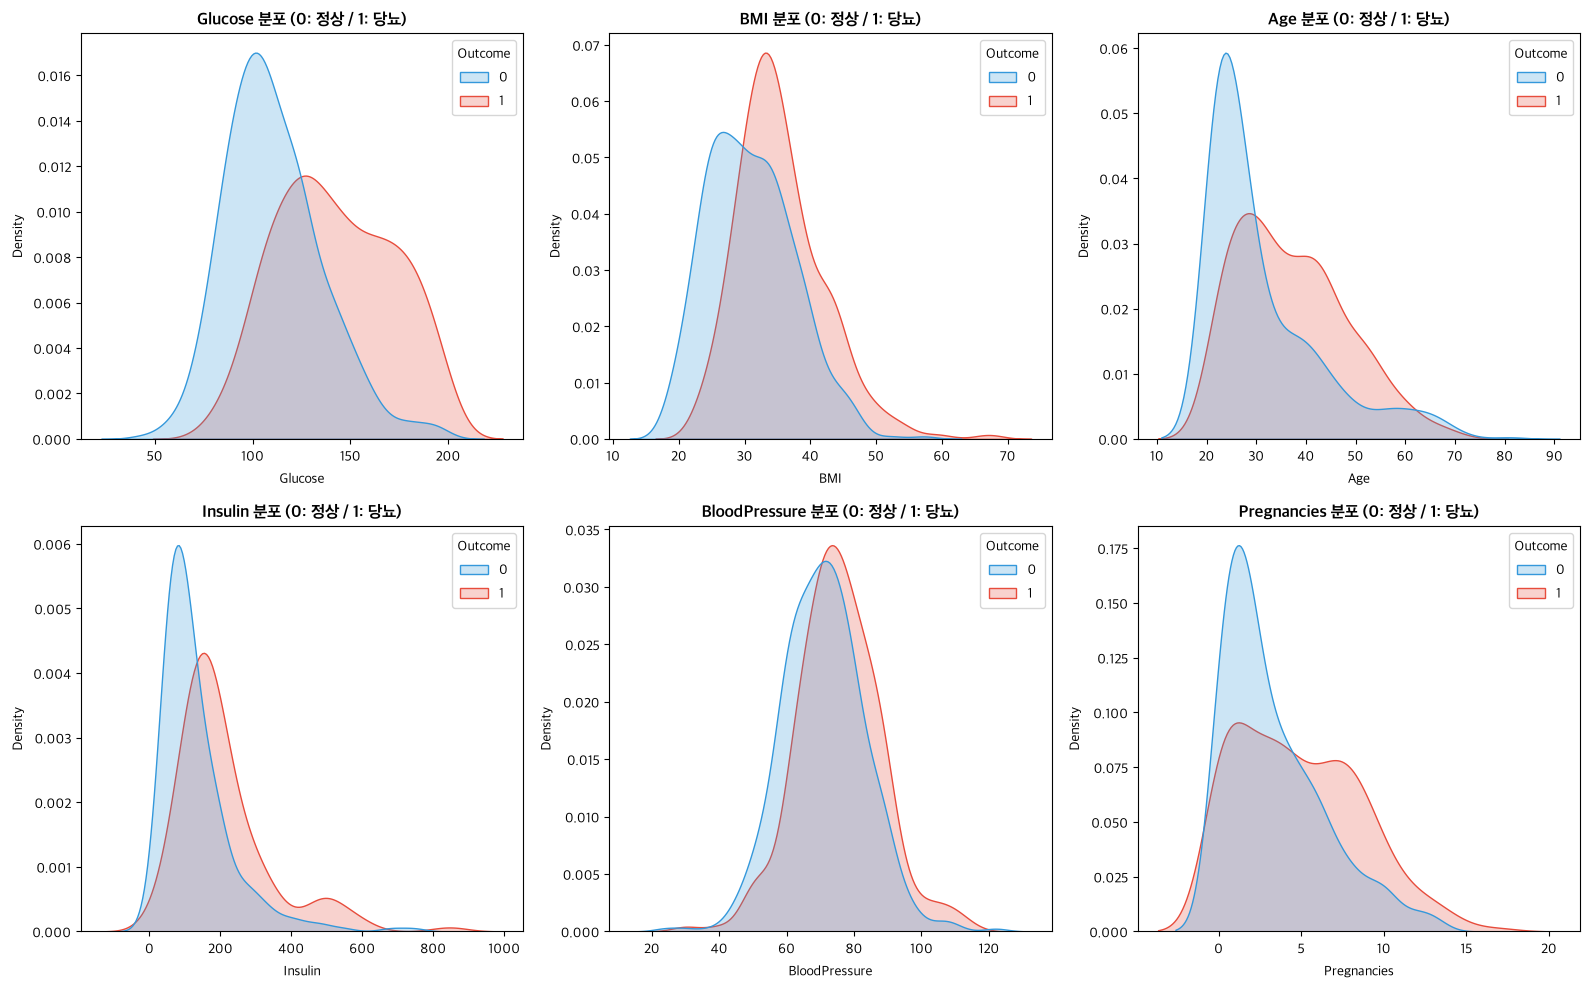

In [4]:
# 1) 당뇨 유무에 따른 주요 신체 지표 분포 비교
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
features = ['Glucose', 'BMI', 'Age', 'Insulin', 'BloodPressure', 'Pregnancies']

for ax, feature in zip(axes.flatten(), features):
    sns.kdeplot(data=df_clean, x=feature, hue='Outcome', fill=True, common_norm=False, 
                palette={0: '#3498db', 1: '#e74c3c'}, ax=ax)
    ax.set_title(f'{feature} 분포 (0: 정상 / 1: 당뇨)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


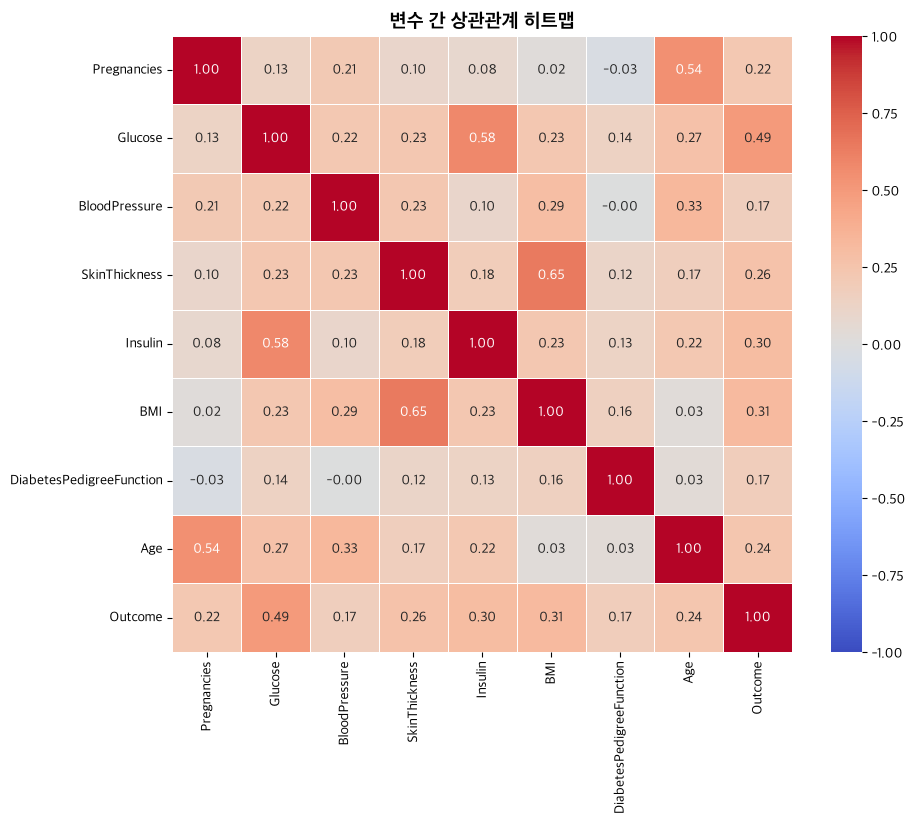

In [5]:
# 2) 상관관계 히트맵 (Correlation Heatmap)
plt.figure(figsize=(10, 8))
corr = df_clean.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("변수 간 상관관계 히트맵", fontsize=14, fontweight='bold')
plt.show()


## 4. 머신러닝 데이터셋 준비
- **X / y 분리**: 특성(X)과 예측 대상 라벨(y) 분리
- **Train / Test 분할**: 80% 학습용, 20% 테스트용 분할 (`stratify=y`로 당뇨 비율 일정하게 유지)
- **결측치 대체 (Imputation)**: 학습 데이터의 중앙값(Median)으로 `NaN` 채우기
- **스케일링 (Standardization)**: 변수별 측정 단위 차이를 맞추기 위해 표준정규분포화(평균 0, 분산 1)

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

# Train/Test 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 중앙값 대체
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# 표준화 스케일링
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

print(f"학습 데이터 샘플 수: {X_train.shape[0]}건")
print(f"테스트 데이터 샘플 수: {X_test.shape[0]}건")


학습 데이터 샘플 수: 614건
테스트 데이터 샘플 수: 154건


## 5. 예측 모델 구축 및 학습
1. **로지스틱 회귀 (Logistic Regression)**: 데이터가 특정 클래스에 속할 확률을 계산하는 기본 분류 모델
2. **랜덤 포레스트 (Random Forest)**: 수많은 의사결정나무들을 앙상블하여 예측하는 강력한 머신러닝 모델

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. 로지스틱 회귀 학습
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

# 2. 랜덤 포레스트 학습
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_imp, y_train)

print("두 모델 학습이 완료되었습니다!")


두 모델 학습이 완료되었습니다!


## 6. 모델 성능 평가 & 시각화
테스트 데이터를 바탕으로 모델의 정확도, 정밀도, 재현율, F1 점수 및 ROC-AUC를 비교하고 혼동 행렬(Confusion Matrix)을 그립니다.

         정확도 (Accuracy)  정밀도 (Precision)  재현율 (Recall)  F1 점수 (F1)  ROC-AUC
로지스틱 회귀          0.7078           0.6000        0.5000      0.5455    0.813
랜덤 포레스트          0.7662           0.6957        0.5926      0.6400    0.821


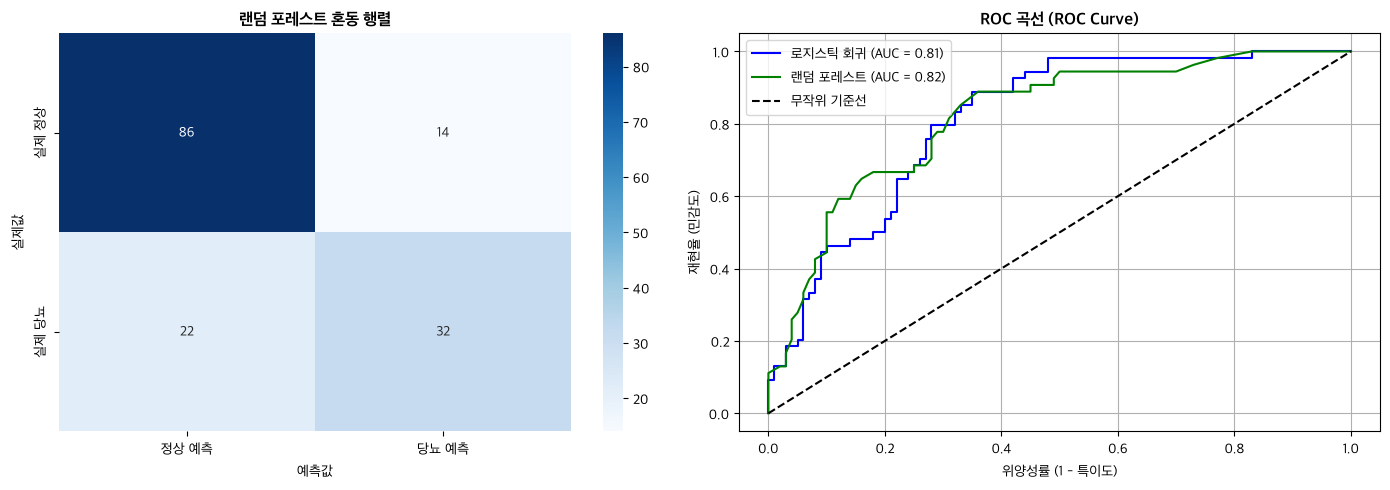

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

# 예측값 및 예측 확률 계산
y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

y_pred_rf = rf_model.predict(X_test_imp)
y_prob_rf = rf_model.predict_proba(X_test_imp)[:, 1]

# 성능 비교 테이블
metrics = {
    '정확도 (Accuracy)': [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_rf)],
    '정밀도 (Precision)': [precision_score(y_test, y_pred_lr), precision_score(y_test, y_pred_rf)],
    '재현율 (Recall)': [recall_score(y_test, y_pred_lr), recall_score(y_test, y_pred_rf)],
    'F1 점수 (F1)': [f1_score(y_test, y_pred_lr), f1_score(y_test, y_pred_rf)],
    'ROC-AUC': [roc_auc_score(y_test, y_prob_lr), roc_auc_score(y_test, y_prob_rf)]
}
eval_df = pd.DataFrame(metrics, index=['로지스틱 회귀', '랜덤 포레스트']).round(4)
print(eval_df)

# 시각화 (Confusion Matrix & ROC Curve)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 혼동 행렬
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], 
            xticklabels=['정상 예측', '당뇨 예측'], yticklabels=['실제 정상', '실제 당뇨'])
axes[0].set_title("랜덤 포레스트 혼동 행렬", fontsize=12, fontweight='bold')
axes[0].set_xlabel("예측값")
axes[0].set_ylabel("실제값")

# ROC 곡선
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

axes[1].plot(fpr_lr, tpr_lr, label=f"로지스틱 회귀 (AUC = {roc_auc_score(y_test, y_prob_lr):.2f})", color='blue')
axes[1].plot(fpr_rf, tpr_rf, label=f"랜덤 포레스트 (AUC = {roc_auc_score(y_test, y_prob_rf):.2f})", color='green')
axes[1].plot([0, 1], [0, 1], 'k--', label='무작위 기준선')
axes[1].set_title("ROC 곡선 (ROC Curve)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("위양성률 (1 - 특이도)")
axes[1].set_ylabel("재현율 (민감도)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 7. 어떤 변수가 당뇨 예측에 가장 결정적일까? (특성 중요도)

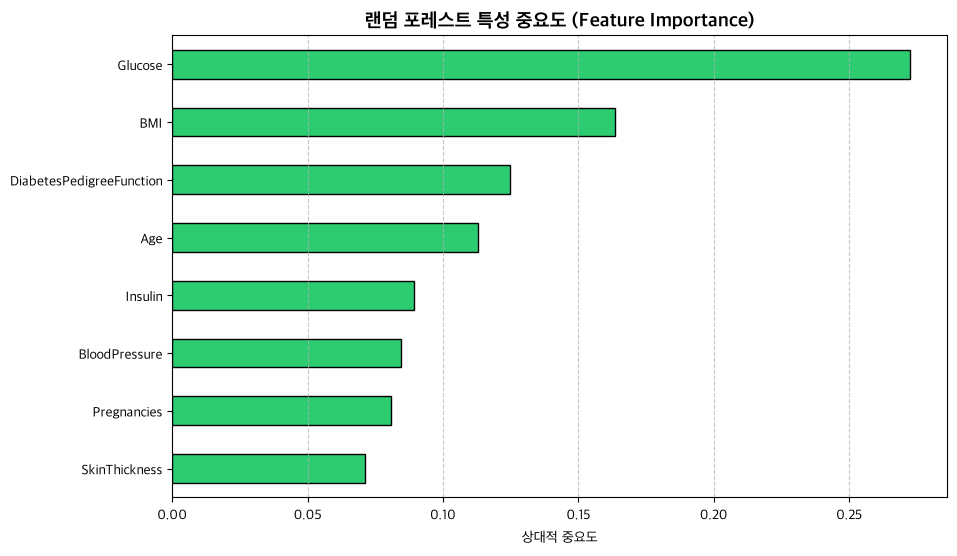

In [9]:
# 특성 중요도 (Feature Importance) 시각화
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
importance.plot(kind='barh', color='#2ecc71', edgecolor='black')
plt.title("랜덤 포레스트 특성 중요도 (Feature Importance)", fontsize=14, fontweight='bold')
plt.xlabel("상대적 중요도")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()
